## Feature Selection based on Shannon Information Theory (descriptive analysis)

This section is a **standalone, descriptive analysis**, separate from the
classification pipeline of the previous sections. Its goal is to study the
candidate features through the lens of **information theory**, as discussed in
the course, and to motivate the feature-selection choices.

Two complementary questions are addressed:

- **Relevance** (per feature): how much information does a single feature carry
  about the `presence` label? The standard linear criterion (ANOVA F-test, the
  same `f_classif` used inside the pipeline) is compared against the
  **mutual information** `I(feature; presence)`, which makes no linearity
  assumption. A **bootstrap** provides confidence intervals on the mutual
  information, and a **label-permutation null** provides a significance
  threshold, addressing the estimation-bias problem (mutual information is
  systematically overestimated on small samples).

- **Redundancy** (per subset): individually informative features may be
  redundant with one another. **mRMR** (minimum-Redundancy-Maximum-Relevance)
  selects features that are informative *and* non-redundant, making the
  redundancy term `Red = I(S;R1) + I(S;R2) - I(S;R1,R2)` visible: the rate
  features, all derived from the same firing activity, are individually
  informative but mutually redundant.

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
import os

In [ ]:
# ====================================================================
# FEATURE GROUPS
# ====================================================================
# The candidate features are grouped by the coding aspect they describe.
# The grouping is used only for colouring and readability of the figures.

feature_groups = {
    # Rate / count code
    "n_spikes_loading": "rate",
    "FR_loading_Hz":    "rate",
    "FR_Q1_Hz":         "rate",
    "FR_Q2_Hz":         "rate",
    "FR_Q3_Hz":         "rate",
    "FR_Q4_Hz":         "rate",
    "FR_slope":         "rate",

    # ISI statistics
    "mean_ISI_loading_s":   "isi",
    "std_ISI_loading_s":    "isi",
    "median_ISI_loading_s": "isi",
    "min_ISI_loading_s":    "isi",
    "max_ISI_loading_s":    "isi",
    "IQR_ISI_loading_s":    "isi",

    # Temporal activity
    "active_span_loading_rel": "activity",

    # Variability / regularity (timing code)
    "CV_ISI_loading":      "timing",
    "CV2_mean_loading":    "timing",
    "LV_loading":          "timing",
    "ISI_skewness_loading":"timing",
    "burstiness_loading":  "timing",
}

group_color = {
    "rate":     "#185FA5",   # blue
    "isi":      "#0F6E56",   # teal
    "activity": "#854F0B",   # amber
    "timing":   "#C0392B",   # red
}

group_label = {
    "rate":     "Rate / count code",
    "isi":      "ISI statistics",
    "activity": "Activity span",
    "timing":   "Timing / regularity",
}

The following cell defines the analysis functions: the mutual-information estimators, the **relevance** table (ANOVA F-test vs mutual information, with bootstrap confidence intervals and a permutation significance threshold), and the **mRMR** selection.

In [2]:
# ====================================================================
# 1. HELPER FUNCTIONS
# ====================================================================

# MUTUAL INFORMATION BETWEEN EACH FEATURE AND THE LABEL
def mutualInformationScores(X_scaled, y, seed):
    """
    Estimates the mutual information I(feature; presence) for every feature.

    Uses the k-nearest-neighbours estimator of scikit-learn, suitable for
    continuous features. A fixed seed makes the estimate reproducible, since
    the estimator is stochastic.
    """

    return mutual_info_classif(
        X_scaled,
        y,
        discrete_features=False,
        random_state=seed,
        n_neighbors=3
    )


# MUTUAL INFORMATION BETWEEN TWO CONTINUOUS FEATURES
def mutualInformationPair(feature_a, feature_b, seed):
    """
    Estimates the mutual information between two continuous features.

    This is used by mRMR to quantify the redundancy between an already
    selected feature and a candidate one.
    """

    return mutual_info_regression(
        feature_a.reshape(-1, 1),
        feature_b,
        discrete_features=False,
        random_state=seed,
        n_neighbors=3
    )[0]


# ====================================================================
# 2. RELEVANCE: ANOVA F-TEST vs MUTUAL INFORMATION
# ====================================================================

def computeRelevanceTable(
    df,
    seed,
    n_bootstrap=200,
    n_permutations=200
):
    """
    Computes, for every candidate feature:

    - the ANOVA F-test score (linear relevance, as in SelectKBest/f_classif);
    - the mutual information I(feature; presence) (non-linear relevance);
    - a bootstrap 95% confidence interval on the mutual information;
    - a per-feature significance threshold (95th percentile of the mutual
      information obtained under label permutation, i.e. pure sampling bias);
    - the mean permutation value, used as a bias estimate for optional
      bootstrap-style subtraction.
    """

    # 1. Standardize the features (median imputation of residual NaNs)
    X = df[feature_names].copy()
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(X.median())

    X_scaled = StandardScaler().fit_transform(X)
    y = df[label_name].to_numpy()


    # 2. ANOVA F-test (linear criterion)
    f_scores, _ = f_classif(X_scaled, y)


    # 3. Mutual information (point estimate)
    mi_point = mutualInformationScores(X_scaled, y, seed)


    # 4. Bootstrap confidence interval on the mutual information
    generator = np.random.default_rng(seed)
    n_samples = len(y)

    bootstrap_scores = np.empty(
        (n_bootstrap, len(feature_names))
    )

    for b in range(n_bootstrap):

        sample_idx = generator.integers(
            0,
            n_samples,
            n_samples
        )

        # Make sure both classes are present in the resample
        if len(np.unique(y[sample_idx])) < 2:
            hard_idx = np.where(y == 1)[0][:2]
            sample_idx = np.r_[sample_idx, hard_idx]

        bootstrap_scores[b] = mutualInformationScores(
            X_scaled[sample_idx],
            y[sample_idx],
            seed + b + 1
        )

    mi_low = np.percentile(bootstrap_scores, 2.5, axis=0)
    mi_high = np.percentile(bootstrap_scores, 97.5, axis=0)


    # 5. Permutation null: mutual information from sampling bias only
    null_scores = np.empty(
        (n_permutations, len(feature_names))
    )

    for p in range(n_permutations):

        y_permuted = generator.permutation(y)

        null_scores[p] = mutualInformationScores(
            X_scaled,
            y_permuted,
            seed + 1000 + p
        )

    mi_significance = np.percentile(null_scores, 95, axis=0)
    mi_bias = null_scores.mean(axis=0)


    # 6. Assemble the relevance table
    relevance_table = pd.DataFrame({
        "feature":       feature_names,
        "group":         [feature_groups[f] for f in feature_names],
        "F_score":       f_scores,
        "MI":            mi_point,
        "MI_low":        mi_low,
        "MI_high":       mi_high,
        "MI_significance": mi_significance,
        "MI_bias":       mi_bias,
        "MI_corrected":  np.clip(mi_point - mi_bias, 0, None),
    })

    return relevance_table


# ====================================================================
# 3. REDUNDANCY: mRMR SELECTION (STEP BY STEP)
# ====================================================================

def mrmrSelection(
    df,
    seed,
    k=8
):
    """
    Greedy mRMR feature selection (difference variant, MID).

    At every step the selected feature is the one maximising
        relevance(feature) - mean_redundancy(feature, already_selected)
    where relevance is I(feature; presence) and redundancy is the average
    mutual information between the candidate and the already selected features.

    Returns an ordered table with the relevance and redundancy bookkeeping,
    so the relevance/redundancy trade-off can be plotted.
    """

    # 1. Standardize the features
    X = df[feature_names].copy()
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(X.median())

    X_scaled = StandardScaler().fit_transform(X)
    y = df[label_name].to_numpy()


    # 2. Relevance of every feature with respect to the label
    relevance = dict(
        zip(
            feature_names,
            mutualInformationScores(X_scaled, y, seed)
        )
    )

    # 3. Quick access to each feature column
    column = {
        f: X_scaled[:, i]
        for i, f in enumerate(feature_names)
    }


    # 4. Greedy selection
    selected = []
    remaining = list(feature_names)
    selection_rows = []

    # Cache of pairwise redundancies (symmetric)
    redundancy_cache = {}

    def averageRedundancy(candidate, chosen):

        if not chosen:
            return 0.0

        values = []

        for c in chosen:

            key = tuple(sorted((candidate, c)))

            if key not in redundancy_cache:
                redundancy_cache[key] = mutualInformationPair(
                    column[candidate],
                    column[c],
                    seed
                )

            values.append(redundancy_cache[key])

        return float(np.mean(values))


    for step in range(min(k, len(feature_names))):

        best_feature = None
        best_score = -np.inf
        best_relevance = None
        best_redundancy = None

        for candidate in remaining:

            candidate_relevance = relevance[candidate]
            candidate_redundancy = averageRedundancy(candidate, selected)

            mrmr_score = candidate_relevance - candidate_redundancy

            if mrmr_score > best_score:
                best_feature = candidate
                best_score = mrmr_score
                best_relevance = candidate_relevance
                best_redundancy = candidate_redundancy

        selected.append(best_feature)
        remaining.remove(best_feature)

        selection_rows.append({
            "step":       step + 1,
            "feature":    best_feature,
            "group":      feature_groups[best_feature],
            "relevance":  best_relevance,
            "redundancy": best_redundancy,
            "mrmr_score": best_score,
        })

    return pd.DataFrame(selection_rows)

Here one representative feature file is selected per phantom and the information-theoretic analysis is run on all three, reusing the same loading convention of the classification pipeline.

In [12]:
# ====================================================================
# 4. SELECT ONE REPRESENTATIVE FILE PER PHANTOM
# ====================================================================
# The information-theoretic analysis compares the three phantoms. For each
# phantom a single representative feature file is used (the base RegularSpiking
# encoding), so that each phantom maps to one column in the figures.

label_name = "presence"

feature_names = [
    # Firing-rate features
    "n_spikes_loading",
    "FR_loading_Hz",
    "FR_Q1_Hz",
    "FR_Q2_Hz",
    "FR_Q3_Hz",
    "FR_Q4_Hz",
    "FR_slope",

    # ISI features
    "mean_ISI_loading_s",
    "std_ISI_loading_s",
    "median_ISI_loading_s",
    "min_ISI_loading_s",
    "max_ISI_loading_s",
    "IQR_ISI_loading_s",

    # Temporal activity feature
    "active_span_loading_rel",

    # Variability features
    "CV_ISI_loading",
    "CV2_mean_loading",
    "LV_loading",
    "ISI_skewness_loading",
    "burstiness_loading",
]


features_folder = os.path.join(
    os.getcwd(),
    "labels_features",
)

results_root = os.path.join(
    os.getcwd(),
    "Results",
    "information_analysis",
)
os.makedirs(results_root, exist_ok=True)

phantom_files = {
    "27/04 (high contrast)":  "spike_features_20180427_M1.csv",
    "24/04 (medium contrast)":"spike_features_20180424_M1.csv",
    "18/05 (low contrast)":   "spike_features_20180518_M2.csv",
}

# Reproducible seed per phantom
phantom_seed = {
    "27/04 (high contrast)":  11,
    "24/04 (medium contrast)":22,
    "18/05 (low contrast)":   33,
}


# ====================================================================
# 5. RUN THE ANALYSIS FOR EVERY PHANTOM
# ====================================================================

relevance_tables = {}
mrmr_tables = {}

for phantom_name, file_name in phantom_files.items():

    csv_path = os.path.join(
        features_folder,
        file_name
    )

    print("\n")
    print("=" * 70)
    print(f"INFORMATION ANALYSIS - {phantom_name}")
    print("=" * 70)

    # Load with the same convention used in the pipeline
    df = pd.read_csv(
        csv_path,
        sep=";"
    )

    # Keep only valid labels and numeric features
    for column_name in feature_names + [label_name]:
        df[column_name] = pd.to_numeric(
            df[column_name],
            errors="coerce"
        )

    df = df.dropna(
        subset=[label_name]
    ).reset_index(drop=True)

    df[label_name] = df[label_name].astype(int)

    print(f"Rows: {df.shape[0]}, hard fraction: {df[label_name].mean():.1%}")

    seed = phantom_seed[phantom_name]

    relevance_tables[phantom_name] = computeRelevanceTable(df, seed=seed)
    mrmr_tables[phantom_name] = mrmrSelection(df, seed=seed, k=8)

    print(
        "mRMR order:",
        " > ".join(mrmr_tables[phantom_name]["feature"])
    )



INFORMATION ANALYSIS - 27/04 (high contrast)
Rows: 252, hard fraction: 9.5%
mRMR order: mean_ISI_loading_s > LV_loading > active_span_loading_rel > min_ISI_loading_s > FR_Q1_Hz > CV_ISI_loading > IQR_ISI_loading_s > CV2_mean_loading


INFORMATION ANALYSIS - 24/04 (medium contrast)
Rows: 252, hard fraction: 18.3%
mRMR order: FR_loading_Hz > LV_loading > active_span_loading_rel > FR_slope > max_ISI_loading_s > n_spikes_loading > min_ISI_loading_s > FR_Q2_Hz


INFORMATION ANALYSIS - 18/05 (low contrast)
Rows: 252, hard fraction: 12.7%
mRMR order: max_ISI_loading_s > min_ISI_loading_s > active_span_loading_rel > CV2_mean_loading > FR_Q3_Hz > FR_Q4_Hz > median_ISI_loading_s > LV_loading


**Figure A — relevance.** For every feature the normalized ANOVA F-score and the mutual information are shown side by side. Error bars are the bootstrap 95% interval on the mutual information; the dashed line is the permutation significance threshold.

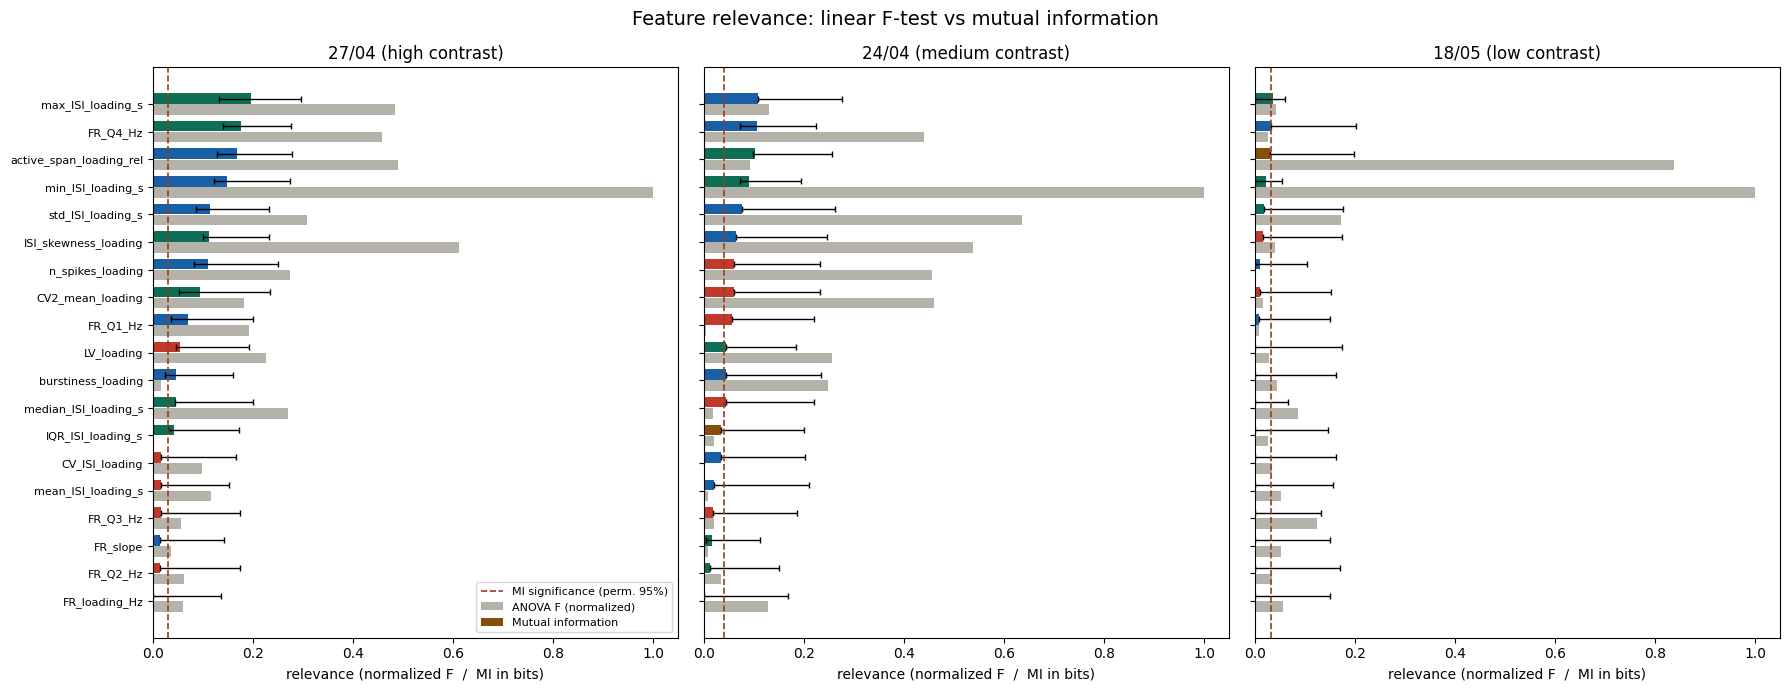

In [13]:
# ====================================================================
# 6. FIGURE A - RELEVANCE: ANOVA F-TEST vs MUTUAL INFORMATION
# ====================================================================
# One column per phantom. For every feature, the normalized ANOVA F-score and
# the mutual information are shown side by side. Error bars are the bootstrap
# 95% interval on the mutual information; the dashed line is the permutation
# significance threshold (mutual information expected from sampling bias alone).

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 7),
    sharey=True
)

for ax, (phantom_name, table) in zip(axes, relevance_tables.items()):

    # Order features by mutual information (descending)
    table_sorted = table.sort_values(
        "MI",
        ascending=True
    ).reset_index(drop=True)

    positions = np.arange(len(table_sorted))

    # Normalize the F-score to [0, 1] for visual comparison with MI
    f_norm = table_sorted["F_score"] / table_sorted["F_score"].max()

    # Bars: F-score (light) and MI (coloured by group)
    bar_colors = [
        group_color[g] for g in table_sorted["group"]
    ]

    ax.barh(
        positions - 0.2,
        f_norm,
        height=0.38,
        color="#B4B2A9",
        label="ANOVA F (normalized)"
    )

    ax.barh(
        positions + 0.2,
        table_sorted["MI"],
        height=0.38,
        color=bar_colors,
        xerr=[
            np.clip(table_sorted["MI"] - table_sorted["MI_low"], 0, None),
            np.clip(table_sorted["MI_high"] - table_sorted["MI"], 0, None),
        ],
        error_kw={"elinewidth": 1, "capsize": 2},
        label="Mutual information"
    )

    # Significance threshold (mean over features, for a single reference line)
    sig = table_sorted["MI_significance"].mean()
    ax.axvline(
        sig,
        color="#993C1D",
        linestyle="--",
        linewidth=1.2,
        label="MI significance (perm. 95%)"
    )

    ax.set_yticks(positions)
    ax.set_yticklabels(
        table_sorted["feature"],
        fontsize=8
    )
    ax.set_title(phantom_name, fontsize=12)
    ax.set_xlabel("relevance (normalized F  /  MI in bits)")

axes[0].legend(
    loc="lower right",
    fontsize=8
)

fig.suptitle(
    "Feature relevance: linear F-test vs mutual information",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    os.path.join(results_root, "relevance_anova_vs_mi.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

**Figure B — redundancy.** The mRMR score at each step is decomposed into its relevance (upward) and redundancy penalty (downward) components, in selection order. Redundant rate features are dropped early despite being individually relevant.

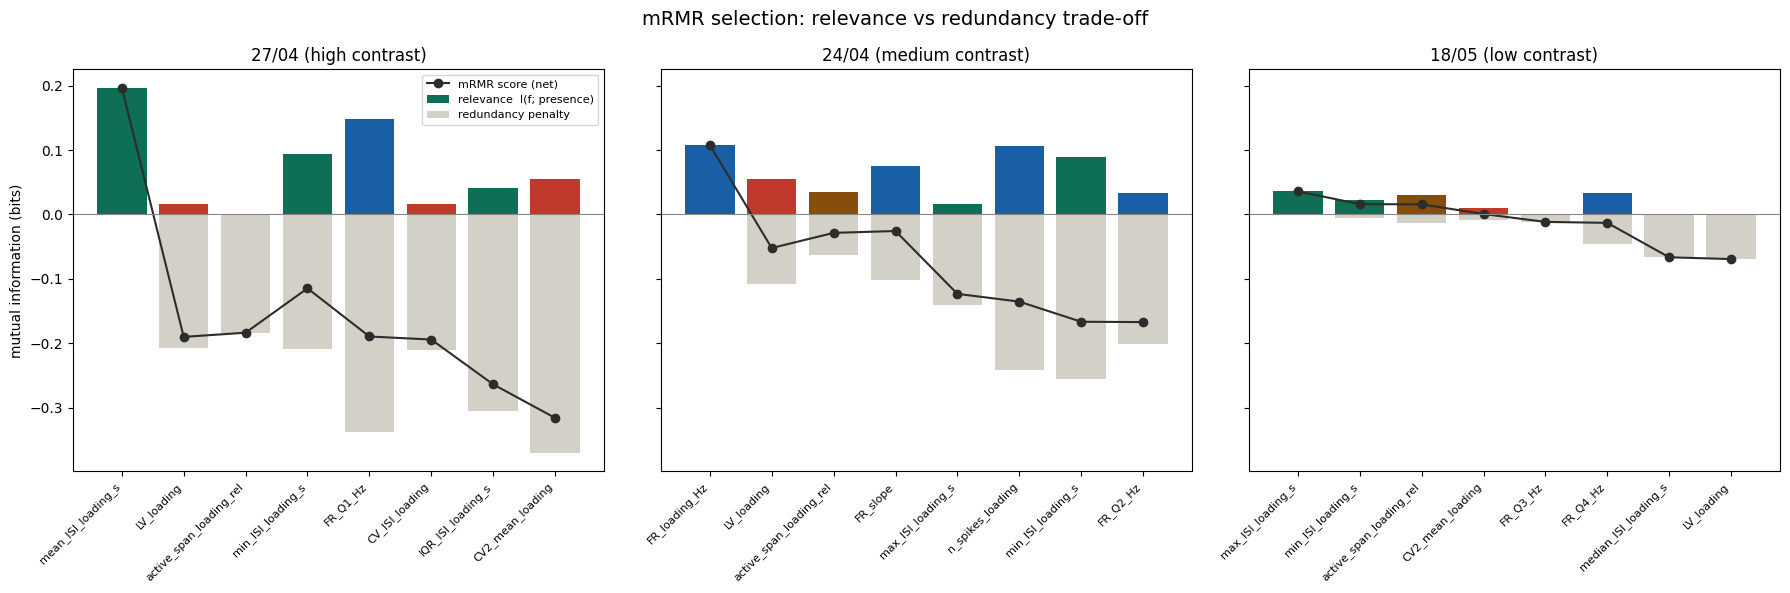

In [14]:
# ====================================================================
# 7. FIGURE B - REDUNDANCY: mRMR SELECTION STEP BY STEP
# ====================================================================
# One column per phantom. The mRMR score at each step is decomposed into its
# relevance (positive) and redundancy penalty (negative) components. Features
# are shown in selection order; the colour encodes the feature group. Rate
# features that are individually relevant are dropped early because of their
# mutual redundancy.

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    sharey=True
)

for ax, (phantom_name, table) in zip(axes, mrmr_tables.items()):

    positions = np.arange(len(table))

    bar_colors = [
        group_color[g] for g in table["group"]
    ]

    # Relevance (upward) and redundancy penalty (downward)
    ax.bar(
        positions,
        table["relevance"],
        color=bar_colors,
        label="relevance  I(f; presence)"
    )

    ax.bar(
        positions,
        -table["redundancy"],
        color="#D3D1C7",
        label="redundancy penalty"
    )

    # Net mRMR score as a line
    ax.plot(
        positions,
        table["mrmr_score"],
        color="#2C2C2A",
        marker="o",
        linewidth=1.5,
        label="mRMR score (net)"
    )

    ax.axhline(0, color="#888780", linewidth=0.8)

    ax.set_xticks(positions)
    ax.set_xticklabels(
        table["feature"],
        rotation=45,
        ha="right",
        fontsize=8
    )
    ax.set_title(phantom_name, fontsize=12)

axes[0].set_ylabel("mutual information (bits)")
axes[0].legend(
    loc="upper right",
    fontsize=8
)

fig.suptitle(
    "mRMR selection: relevance vs redundancy trade-off",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    os.path.join(results_root, "mrmr_selection.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()